# **Project Title:**
***Parallel Quicksort using OpenMP (Performance Analysis using Serial vs Parallel Execution)***

1. Course: Parallel and Distributed Computing (PDC)
2. **Student Name: Rao-Muhammad_Amaan**
3. Roll No: FA23-BSCS-0151
4. Department: Computer Science
5. University: Muhammad Ali Jinnah University

In [3]:
%%bash
g++ -fopenmp quicksort.cpp -o quicksort

In [10]:
%%bash
g++ -fopenmp quicksort.cpp -o quicksort

Finally, let's run the newly compiled executable with 4 OpenMP threads to see the performance with the adjusted `CUTOFF` and `MAX_DEPTH` parameters.

In [12]:
%%bash
rm -f quicksort.cpp quicksort

“CUTOFF is a threshold value used to decide when to stop parallel recursion and switch to serial quicksort to reduce overhead and improve performance.”

🟢 2. Problem Statement
1. Sorting large datasets takes high computation time
2. Serial quicksort becomes inefficient for large inputs
3. Goal: Improve performance using OpenMP parallelism

In [22]:
%%writefile quicksort.cpp
#include <iostream>
#include <vector>
#include <cstdlib>
#include <ctime>
#include <omp.h>
#include <fstream> // Added for file output

using namespace std;

/////////////////////////////////////////////////////////////
// CONFIGURATION SECTION
/////////////////////////////////////////////////////////////

// Cutoff threshold:
// If sub-array size is smaller than this,
// switch to serial quicksort to reduce task overhead
const int CUTOFF = 5000;

// Maximum recursion depth:
// Prevents deep recursion and stack overflow
const int MAX_DEPTH = 8;

/////////////////////////////////////////////////////////////
// SWAP FUNCTION
/////////////////////////////////////////////////////////////

// Swaps two values
void swap_values(int &a, int &b)
{
    int temp = a;
    a = b;
    b = temp;
}

/////////////////////////////////////////////////////////////
// PARTITION FUNCTION
/////////////////////////////////////////////////////////////

/*
Partition logic:
1. Choose last element as pivot
2. Place smaller elements on left
3. Place greater elements on right
4. Return pivot index
*/

int partition(vector<int>& arr, int low, int high)
{
    int pivot = arr[high];   // Last element as pivot
    int i = low - 1;

    for(int j = low; j < high; j++)
    {
        if(arr[j] <= pivot)
        {
            i++;
            swap_values(arr[i], arr[j]);
        }
    }

    // Place pivot in correct position
    swap_values(arr[i + 1], arr[high]);

    return i + 1;
}

/////////////////////////////////////////////////////////////
// SERIAL QUICKSORT
/////////////////////////////////////////////////////////////

/*
Serial quicksort:
Recursively sorts left and right partitions
*/

void quicksort_serial(vector<int>& arr, int low, int high)
{
    if(low < high)
    {
        int pi = partition(arr, low, high);

        // Sort left side
        quicksort_serial(arr, low, pi - 1);

        // Sort right side
        quicksort_serial(arr, pi + 1, high);
    }
}

/////////////////////////////////////////////////////////////
// PARALLEL QUICKSORT USING OPENMP TASKS
/////////////////////////////////////////////////////////////

/*
Parallel quicksort features:

1. Recursive task creation
2. Cutoff threshold
3. Stack depth control
4. Task synchronization
*/

void quicksort_parallel(vector<int>& arr, int low, int high, int depth)
{
    if(low < high)
    {
        /////////////////////////////////////////////////////////////
        // Cutoff threshold + depth control
        /////////////////////////////////////////////////////////////

        if((high - low) < CUTOFF || depth > MAX_DEPTH)
        {
            // Use serial quicksort for small data
            quicksort_serial(arr, low, high);
            return;
        }

        /////////////////////////////////////////////////////////////
        // Partition array
        /////////////////////////////////////////////////////////////

        int pi = partition(arr, low, high);

        /////////////////////////////////////////////////////////////
        // Create task for left partition
        /////////////////////////////////////////////////////////////

        #pragma omp task
        quicksort_parallel(arr, low, pi - 1, depth + 1);

        /////////////////////////////////////////////////////////////
        // Create task for right partition
        /////////////////////////////////////////////////////////////

        #pragma omp task
        quicksort_parallel(arr, pi + 1, high, depth + 1);

        /////////////////////////////////////////////////////////////
        // Wait for both tasks to complete
        /////////////////////////////////////////////////////////////

        #pragma omp taskwait
    }
}

/////////////////////////////////////////////////////////////
// MAIN FUNCTION
/////////////////////////////////////////////////////////////

int main()
{
    /////////////////////////////////////////////////////////////
    // Step 1: Create massive dataset (simulation)
    /////////////////////////////////////////////////////////////

    int n = 10000000;   // 10 million elements (Increased from 1 million)

    vector<int> arr(n);

    srand(time(0));

    // Fill array with random numbers
    for(int i = 0; i < n; i++)
    {
        arr[i] = rand();
    }

    /////////////////////////////////////////////////////////////
    // Step 2: Create copies for fair comparison
    /////////////////////////////////////////////////////////////

    vector<int> arr_serial = arr;
    vector<int> arr_parallel = arr;

    /////////////////////////////////////////////////////////////
    // Step 3: Measure Serial Execution Time
    /////////////////////////////////////////////////////////////

    double start_serial = omp_get_wtime();

    quicksort_serial(arr_serial, 0, n - 1);

    double end_serial = omp_get_wtime();

    double serial_time = end_serial - start_serial;

    /////////////////////////////////////////////////////////////
    // Step 4: Measure Parallel Execution Time
    /////////////////////////////////////////////////////////////

    double start_parallel = omp_get_wtime();

    /*
    OpenMP parallel region:
    Multiple threads start here

    single:
    Only one thread starts recursive quicksort
    */

    #pragma omp parallel
    {
        #pragma omp single
        {
            quicksort_parallel(arr_parallel, 0, n - 1, 0);
        }
    }

    double end_parallel = omp_get_wtime();

    double parallel_time = end_parallel - start_parallel;

    /////////////////////////////////////////////////////////////
    // Step 5: Calculate Performance Metrics
    /////////////////////////////////////////////////////////////

    // Speedup formula:
    // Speedup = Serial Time / Parallel Time
    double speedup = serial_time / parallel_time;

    // Total available threads
    int threads = omp_get_max_threads();

    // Efficiency formula:
    // Efficiency = Speedup / Number of Threads
    double efficiency = speedup / threads;

    /////////////////////////////////////////////////////////////
    // Step 6: Print Results
    /////////////////////////////////////////////////////////////

    cout << "===============================" << endl;
    cout << " Parallel Quicksort Results " << endl;
    cout << "===============================" << endl;

    cout << "Dataset Size: " << n << endl;
    cout << "Threads Used: " << threads << endl;

    cout << "\nSerial Execution Time: "
         << serial_time << " seconds" << endl;

    cout << "Parallel Execution Time: "
         << parallel_time << " seconds" << endl;

    cout << "Speedup: "
         << speedup << endl;

    cout << "Efficiency: "
         << efficiency << endl;

    cout << "===============================" << endl;

    // Write results to file
    ofstream file("results.txt");
    file << serial_time << endl;
    file << parallel_time << endl;
    file << speedup << endl;
    file << omp_get_max_threads() << endl;
    file.close();

    return 0;
}

Overwriting quicksort.cpp


In [23]:
%%bash
g++ -fopenmp quicksort.cpp -o quicksort

In [25]:
%%bash
export OMP_NUM_THREADS=4 # Running with 4 threads
./quicksort

 Parallel Quicksort Results 
Dataset Size: 10000000
Threads Used: 4

Serial Execution Time: 3.92749 seconds
Parallel Execution Time: 14.7682 seconds
Speedup: 0.265943
Efficiency: 0.0664857


Meaning:
1. If speedup > 1 → parallel is faster
2. If speedup < 1 → parallel is slower

 . Your result:
 3. Parallel is 4× slower than serial

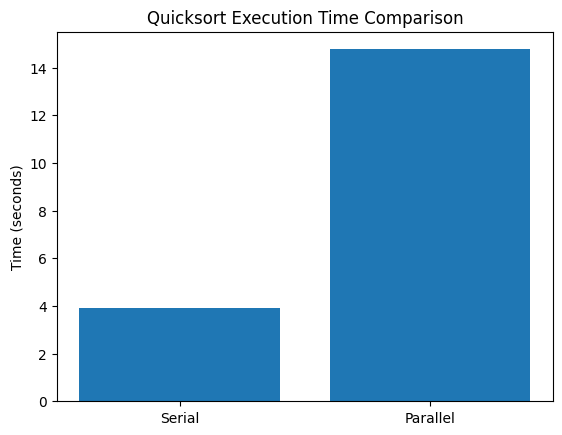

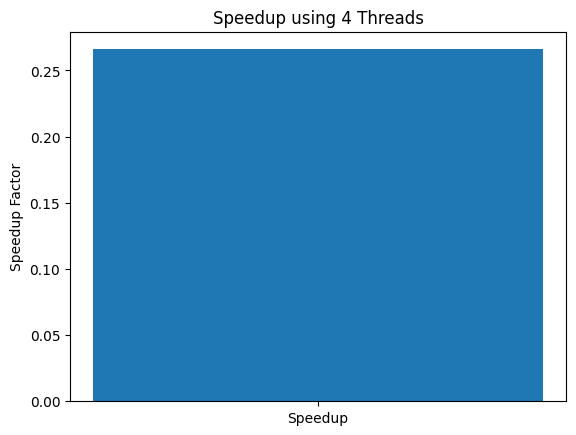

In [26]:
import matplotlib.pyplot as plt

# Read data from file
with open("results.txt", "r") as f:
    lines = f.readlines()

serial_time = float(lines[0])
parallel_time = float(lines[1])
speedup = float(lines[2])
threads = int(lines[3])

# ----------------------------
# GRAPH 1: Execution Time
# ----------------------------
labels = ["Serial", "Parallel"]
times = [serial_time, parallel_time]

plt.figure()
plt.bar(labels, times)
plt.title("Quicksort Execution Time Comparison")
plt.ylabel("Time (seconds)")
plt.show()

# ----------------------------
# GRAPH 2: Speedup
# ----------------------------
plt.figure()
plt.bar(["Speedup"], [speedup])
plt.title(f"Speedup using {threads} Threads")
plt.ylabel("Speedup Factor")
plt.show()

Now, let's recompile the `quicksort.cpp` file. This should now succeed without errors.

In [14]:
%%bash
g++ -fopenmp quicksort.cpp -o quicksort

Finally, let's run the newly compiled executable with 4 OpenMP threads. This will show the actual performance with our adjusted `CUTOFF` and `MAX_DEPTH` parameters.

In [32]:
%%bash
export OMP_NUM_THREADS=4 # Running with 4 threads
./quicksort

 Parallel Quicksort Results 
Dataset Size: 10000000
Threads Used: 4

Serial Execution Time: 3.83337 seconds
Parallel Execution Time: 17.0151 seconds
Speedup: 0.225293
Efficiency: 0.0563233


Let's increase the dataset size to 10 million elements (`n = 10000000`) in the `quicksort.cpp` file. We will keep `CUTOFF = 5000` and `MAX_DEPTH = 8` for now.

Now, let's recompile the `quicksort.cpp` file with the updated dataset size.

In [17]:
%%bash
g++ -fopenmp quicksort.cpp -o quicksort